<h1 align="center">CSE 242 Assignment 2</h1>

<h2 align="center">3 Questions, 100 pts</h2>

Your name: ____________________    Student ID: ____________________

## Instruction 

- Submit your assignments onto **Canvas** by the due date. Upload a <code>zip</code> file containing:

    (1) The saved/latest <code>.ipynb</code> file.

    (2) Also save your file into a pdf version, if error appears, save an html version instead (easy to grade for written questions).
    
    (3) All other materials to make your <code>.ipynb</code> file runnable.
    
    **For assignment related questions, please reach TA or grader through EdDiscussion.**
    
- This is an **individual** assignment. All help from others (from the web, books other than text, genAI, or people other than the TA or instructor) must be clearly acknowledged. 
- Most coding parts can be finished with only 1-2 lines of codes.
- Make sure you have installed required packages: <code>scikit-learn</code>.
- Double click to edit each markdown cell.

## Objective 

- **Task 1:** Maximum likelihood estiamtion (math)
- **Task 2:** Linear Regression (with Scikit-learn)
- **Task 3:** Principle Component Analysis (with Scikit-learn)

# Question 1 (Maximum likelihood estiamtion and Posterior, 20 pts) 

Assume we have a coin that has some unknown probability $h$ of coming up heads (and probability $1-h$ of coming up tails). If the coin is flipped five times getting three heads and two tails ($\mathbf{HHHTT}$) then:

(a -- 10pts) What is the maximum likelihood estimate for $h$?

(b -- 10pts) Assume that (before flipping the coin) we have a prior density $p(h)$ for the various values of $h\in [0,1]$. Give the formula for the posterior probability density $p(h \mid \mathbf{HHHTT})$ as a function of the prior $p(h)$.

For Question 1(b), the solution is acceptable if the formula contains an integral.

**Solution (a):** Assume the five flips are independent with the same heads probability $h$. The likelihood of the observed ordered sequence is
$$L(h)=P(\mathbf{HHHTT}\mid h)=h^3(1-h)^2,\qquad 0\le h\le1.$$
For $0<h<1$, the log likelihood and its derivative are
$$\ell(h)=3\log h+2\log(1-h),\qquad \ell'(h)=\frac3h-\frac2{1-h}.$$
Setting the derivative to zero gives $3(1-h)=2h$, hence
$$\boxed{\hat h_{\mathrm{MLE}}=\frac35=0.6.}$$
Since $\ell''(h)=-3/h^2-2/(1-h)^2<0$ and the likelihood is zero at both endpoints, this is the global maximum.

**Solution (b):** By Bayes' rule, the posterior density is
$$\boxed{p(h\mid\mathbf{HHHTT})=
\frac{h^3(1-h)^2p(h)}{\displaystyle\int_0^1 u^3(1-u)^2p(u)\,du},\qquad 0\le h\le1,}$$
and it is zero outside $[0,1]$. Here $u$ is an integration variable, and the denominator normalizes the density; it is positive for a proper prior density. No binomial coefficient is needed for this particular ordered sequence. If only the counts were observed, the factor $\binom53$ would cancel between numerator and denominator.

**If you are not familair with Latex, you may attach a figure/screen-shoot and display the code below.**

In [1]:
from IPython.display import Image
# Replace the figure name
# Image(filename='sample.png') 

# Question 2 (Linear Regression, 40 pts)
In this question, you will be using **Scikit-learn** to empirically apply the Linear Regression model. We will adopt an advertisement dataset **Advertising.csv** from Kaggle. 

### Reading data using Pandas

In [2]:
# Read the dataset you will be working on
# The dataframe loaded with pandas is named as data

import pandas as pd
data = pd.read_csv('Advertising.csv', index_col=0)  # Modify your data path accordingly.

# Take a look at the first 5 rows
data.head()

Out[2]: 
      TV  Radio  Newspaper  Sales
1  230.1   37.8       69.2   22.1
2   44.5   39.3       45.1   10.4
3   17.2   45.9       69.3    9.3
4  151.5   41.3       58.5   18.5
5  180.8   10.8       58.4   12.9


In [3]:
data.shape

Out[3]: (200, 4)


### Features and responses

What are the features?
- **TV:** advertising dollars spent on TV for a single product in a given market (in thousands of dollars)
- **Radio:** advertising dollars spent on Radio
- **Newspaper:** advertising dollars spent on Newspaper

What is the response?
- **Sales:** sales of a single product in a given market (in thousands of items)

What else do we know?
- There are 200 **observations**, and each observation (each row) is a single market.
- **Your main task**: predict the sales of a single product in a given market.
- Since the response variable is continuous, this is a **regression** problem.

### Linear regression

**Pros:** fast, no tuning required, highly interpretable

**Cons:** adopting the linear regression is unlikely to always generate the best predictive accuracy, since Linear Regression presumes a linear relationship between the features and response. This assumption may not always make sense. (But if one can _transform_ the features so that do have a linear relationship, sometimes progress can be made, for example by taking logs.)

**Expression:**

- $y$: the response
- $\beta_0$: the intercept
- $\beta_1$: the coefficient for $x_1$ (the first feature)
- $\beta_i$ is the coefficient for $x_i$ (the ith feature, $i\in \{1, 2, ..., n\}$)

For this regression task:

$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$

The $\beta$ values ($\beta=[\beta_0, \beta_1, \beta_2, \beta_3]$) are called the **model coefficients**. These values are "learned" during the model fitting step using the "least squares" criterion. Then, we can make use of the fitted model to make predictions!

### Prepare the dataset for training use

- Scikit-learn expects X (feature matrix) and y (response vector) to be NumPy arrays.
- Pandas is built on top of NumPy, and exposes numpy methods. Thus, X can be a pandas DataFrame, y can be a pandas Series!

In [4]:
# Prepare the feature X
X = data[['TV', 'Radio', 'Newspaper']]

# check the type and shape of X
print(type(X))
print(X.shape)

<class 'pandas.core.frame.DataFrame'>
(200, 3)


In [5]:
# Prepare the response Y
y = data['Sales']
# check the type and shape of y
print(type(y))
print(y.shape)

<class 'pandas.core.series.Series'>
(200,)


## Question 2.1 (Split the dataset into train and test parts, 5 pts)

For features $X$ and response $y$, use **sklearn** to perform the the splitting of dataset: $80\%$ for train data, $20\%$ for the test data.

In [6]:
# Question 2.1: fix the split so all results are reproducible.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Double check the shape of train and test data:

In [7]:
# default split is 80% for training and 20% for testing
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(160, 3)
(160,)
(40, 3)
(40,)


## Question 2.2 (Train a Linear regression model via Scikit-learn, 10 pts)

Assume you model is named as **model**, and you train the linear regression model to fit on the training data.

In [8]:
# Question 2.2
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(X_train, y_train)

In [9]:
# Take a look at your model coefficients
import numpy as np
print(np.round(model.intercept_, 4))
print([np.round(val, 4) for val in model.coef_])

2.9791
[np.float64(0.0447), np.float64(0.1892), np.float64(0.0028)]


In [10]:
# Match the feature names with the trained coefficients
list(zip(data.columns[:3].tolist(), model.coef_))

Out[10]: 
[('TV', np.float64(0.04472951746871633)),
 ('Radio', np.float64(0.18919505423437652)),
 ('Newspaper', np.float64(0.0027611143413671935))]


## Question 2.3 (Interpreting model coefficients, 10 pts)

The coefficients of each feature are printed above. 

### Your tasks:

- What is the trained linear regression model? 

- **(replace $\beta_i$ below with the trained coefficients, reserve four decimal places, 5 pts)**

$$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$$

- **(Open) question (5 pts)**: how do you interpret the coefficient of **TV** ($\beta_1$)?

### Solution for Question 2.3

Using the training set from the split with `random_state=42`, the fitted model (coefficients rounded to four decimal places) is
$$\widehat{\text{Sales}}=2.9791+0.0447\times\text{TV}+0.1892\times\text{Radio}+0.0028\times\text{Newspaper}.$$

Holding Radio and Newspaper spending fixed, increasing TV advertising spending by $1,000 is associated with an increase of 0.0447 thousand items (about 44.7 items) in predicted sales. This is a conditional association in the fitted model; the observational data alone do not establish a causal effect.

### Making predictions

In [11]:
# Predict sales on the test set. The regression score is R^2.
y_pred = model.predict(X_test)
print(f"Test R^2: {model.score(X_test, y_test):.6f}")

Test R^2: 0.899438


## Model evaluation metrics for regression

Evaluation metrics for classification problems, such as **accuracy**, are not useful for regression problems. Instead, we need evaluation metrics designed for comparing continuous values.  (Since predictions would hardly ever exactly match the measured quantities.)

**Mean Squared Error** (MSE) is the mean of the squared errors:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**Root Mean Squared Error** (RMSE) is a popular evaluation metric for regression, which is defined as the square root of the mean of the squared errors:

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$

## Question 2.4 (Evaluate your predictions on test features with RMSE metric, 5 pts)

Hint: you may calculate MSE using scikit-learn, but RMSE is a little bit different from MSE.

In [12]:
# Question 2.4
from sklearn import metrics
rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
print(f"Test RMSE (TV, Radio, Newspaper): {rmse:.6f} thousand items")

Test RMSE (TV, Radio, Newspaper): 1.781600 thousand items


## Question 2.5 (Does the feature 'Newspaper' help? 10 pts)

Does the feature **Newspaper** contribute or impair the model prediction? Now repeat previous procedure: 

- For features $X$, only select **TV** and **Radio**; response $y$ is unchanged.

- Split the dataset as what you have done before.

- Fit/Train the model on the train data.

- Make predictions on the test data.

- Compute the RMSE of the predictions on the test data.

- **Show your observations!**

**Reminder:** if you use <code>random_state</code> while splitting the dataset, make sure the value of <code>random_state</code> is the same for the two splits. So that the test data only differs in the column of **Newspaper**.

In [13]:
# Question 2.5: use the identical split for a fair feature comparison.
X_reduced = data[['TV', 'Radio']]
X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42
)
model_reduced = LinearRegression().fit(X_train_reduced, y_train_reduced)
y_pred_reduced = model_reduced.predict(X_test_reduced)
rmse_reduced = np.sqrt(metrics.mean_squared_error(y_test_reduced, y_pred_reduced))
print(f"Test RMSE with Newspaper:    {rmse:.6f}")
print(f"Test RMSE without Newspaper: {rmse_reduced:.6f}")
print(f"RMSE change after removing Newspaper: {rmse_reduced - rmse:+.6f}")

Test RMSE with Newspaper:    1.781600
Test RMSE without Newspaper: 1.771425
RMSE change after removing Newspaper: -0.010174


### Observations

The test RMSE is **1.781600 thousand items** with Newspaper and **1.771425 thousand items** without it. Removing Newspaper reduces RMSE by 0.010174 thousand items (about 0.57%). Thus Newspaper slightly impairs prediction on this test split.

Both models use the same 160 training rows and 40 test rows, so the comparison changes only the included features. Newspaper's fitted coefficient is close to zero after accounting for TV and Radio. This result concerns one held-out split; it does not establish that Newspaper is always unhelpful. Repeated splits or cross-validation would provide stronger evidence.

# Question 3 (PCA, 40 pts)

In this question, we will explore how PCA helps with reducing the dimensionality through scikit-learn. We will adopt a simple digits dataset contained in scikit-learn.

In [14]:
# import libraries
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; 
sns.set()

In [15]:
from sklearn.datasets import load_digits
data_digit = load_digits()
data_digit.data.shape

Out[15]: (1797, 64)


As you have seen above, there are 1797 rows and 64 columns in this dataset. Each row denotes the pixel values of an image. Since each image is 8*8 (in pixel), the dimension of each feature is 64. Let's take a look at a few images contained in this dataset.

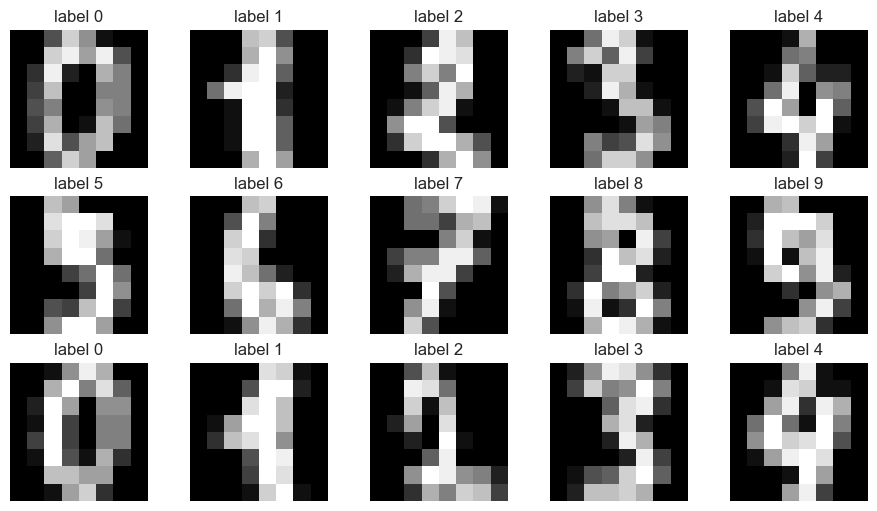

In [16]:
# Display the first 15 digits with consistent color limits for comparison.
def display_digits(imgs):
    fig, axes = plt.subplots(3, 5, figsize=(9, 5), constrained_layout=True)
    for i, ax in enumerate(axes.flat):
        ax.imshow(imgs[i].reshape(8, 8), cmap='gray', vmin=0, vmax=16)
        ax.axis('off')
        ax.set_title(f'label {data_digit.target[i]}')
    plt.show()

display_digits(data_digit.images)

**PCA** finds uncorrelated orthogonal axes (principal components) in a high dimensional space (i.e., 64) to project the feature onto principal components.

## Question 3.1 (PCA and dimensionality deduction with Scikit-learn, 10 pts)

In this question, you may use the implementation of PCA from scikit-learn, as imported below. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Fit the model with feature X (**data_digit.data** for this dataset) and apply the dimensionality reduction on X, keep 2 components.

In [17]:
from sklearn.decomposition import PCA

# Question 3.1: center the pixel values and retain the first two components.
pca = PCA(n_components=2, svd_solver='full')
projected = pca.fit_transform(data_digit.data)
print(data_digit.data.shape)
print(projected.shape)

(1797, 64)
(1797, 2)


With the reduced dimension of features, we can now visualize the projected/reduced features in a 2-dimension plot as below. There are hardly any overlaps between digit 0 and any other digits. While in the central area of the figure, features are not well separable.

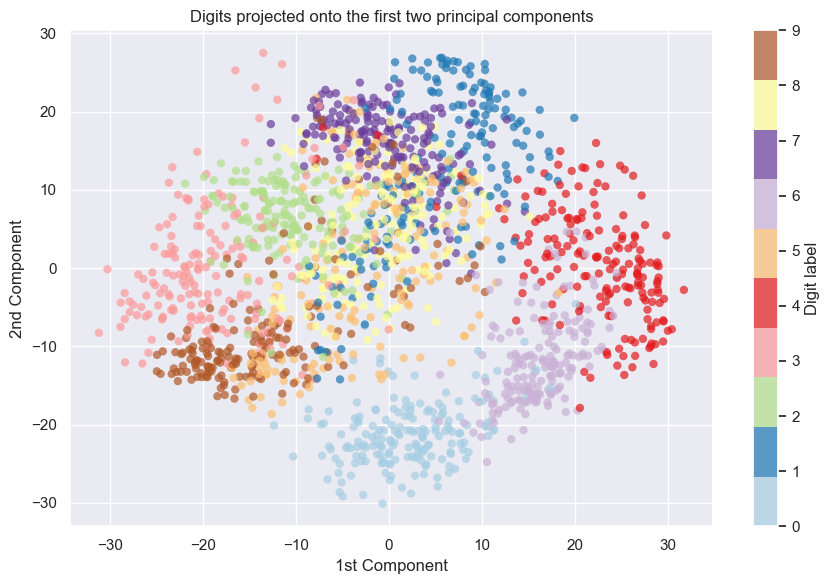

In [18]:
plt.figure(figsize=(9, 6))
plt.scatter(projected[:, 0], projected[:, 1],
            c=data_digit.target, edgecolor='none', alpha=0.7,
            cmap=plt.get_cmap('Paired', 10))
plt.xlabel('1st Component')
plt.ylabel('2nd Component')
plt.colorbar(ticks=range(10), label='Digit label')
plt.title('Digits projected onto the first two principal components')
plt.tight_layout()
plt.show()

## Question 3.2 (How many components do we need? 15 pts)

In practice, suppose you are given a high-dimension dataset, and you are interested in performing a dimension reduciton with PCA. How many conponents do we need? One method is to look at the distribution of the explained variance ratio w.r.t. each component.

In this question, you may use the function <code>explained_variance_ratio</code> in **pca** (with scikit-learn) to address this question. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Print the ratio of variance explained by each of the selected components;

Visualize with matplotlib or seaborn (x axis: $i-th$ component; y axis: the corresponding ratio of explained variance).

Explained variance ratios of the two selected components:
[0.14890594 0.13618771]
Total variance retained by two components: 28.5094%

Explained variance ratio of every component:
Component  1: 0.14890594
Component  2: 0.13618771
Component  3: 0.11794594
Component  4: 0.08409979
Component  5: 0.05782415
Component  6: 0.04916910
Component  7: 0.04315987
Component  8: 0.03661373
Component  9: 0.03353248
Component 10: 0.03078806
Component 11: 0.02372341
Component 12: 0.02272697
Component 13: 0.01821863
Component 14: 0.01773855
Component 15: 0.01467101
Component 16: 0.01409716
Component 17: 0.01318589
Component 18: 0.01248138
Component 19: 0.01017718
Component 20: 0.00905617
Component 21: 0.00889538
Component 22: 0.00797123
Component 23: 0.00767493
Component 24: 0.00722904
Component 25: 0.00695889
Component 26: 0.00596081
Component 27: 0.00575615
Component 28: 0.00515158
Component 29: 0.00489540
Component 30: 0.00428888
Component 31: 0.00373606
Component 32: 0.00353274
Component 33: 0.0033

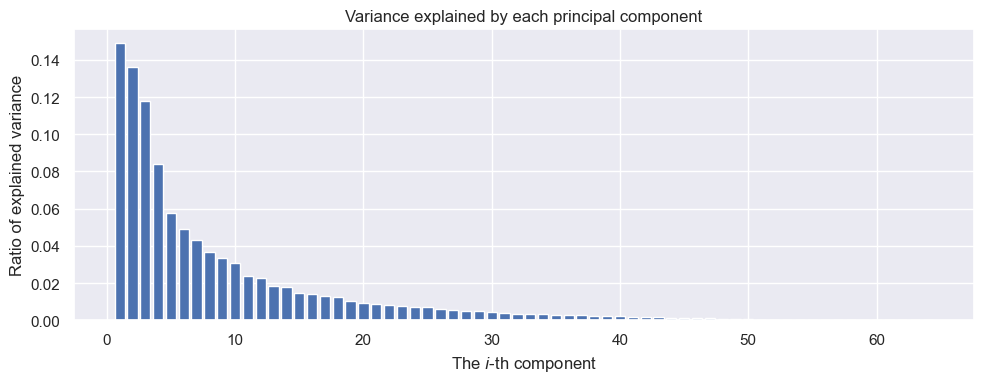

In [19]:
# Question 3.2: report the two selected components, then examine all 64.
print("Explained variance ratios of the two selected components:")
print(pca.explained_variance_ratio_)
print(f"Total variance retained by two components: {pca.explained_variance_ratio_.sum():.4%}")

pca_full = PCA(svd_solver='full').fit(data_digit.data)
ratios = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratios)
print("\nExplained variance ratio of every component:")
for i, ratio in enumerate(ratios, start=1):
    print(f"Component {i:2d}: {ratio:.8f}")
for threshold in (0.80, 0.95):
    count = np.searchsorted(cumulative, threshold) + 1
    print(f"Components needed for {threshold:.0%} variance: {count}")

plt.figure(figsize=(10, 4))
plt.bar(np.arange(1, len(ratios) + 1), ratios)
plt.xlabel('The $i$-th component')
plt.ylabel('Ratio of explained variance')
plt.title('Variance explained by each principal component')
plt.tight_layout()
plt.show()

### How to obtain eigen values and vectors from sklearn PCA

- Eigen values -- <code>your-PCA-model\.explained\_variance\_</code>

- Eigen vectors -- <code>your-PCA-model.components_ </code>

### Eigen vectors (Eigen digits)

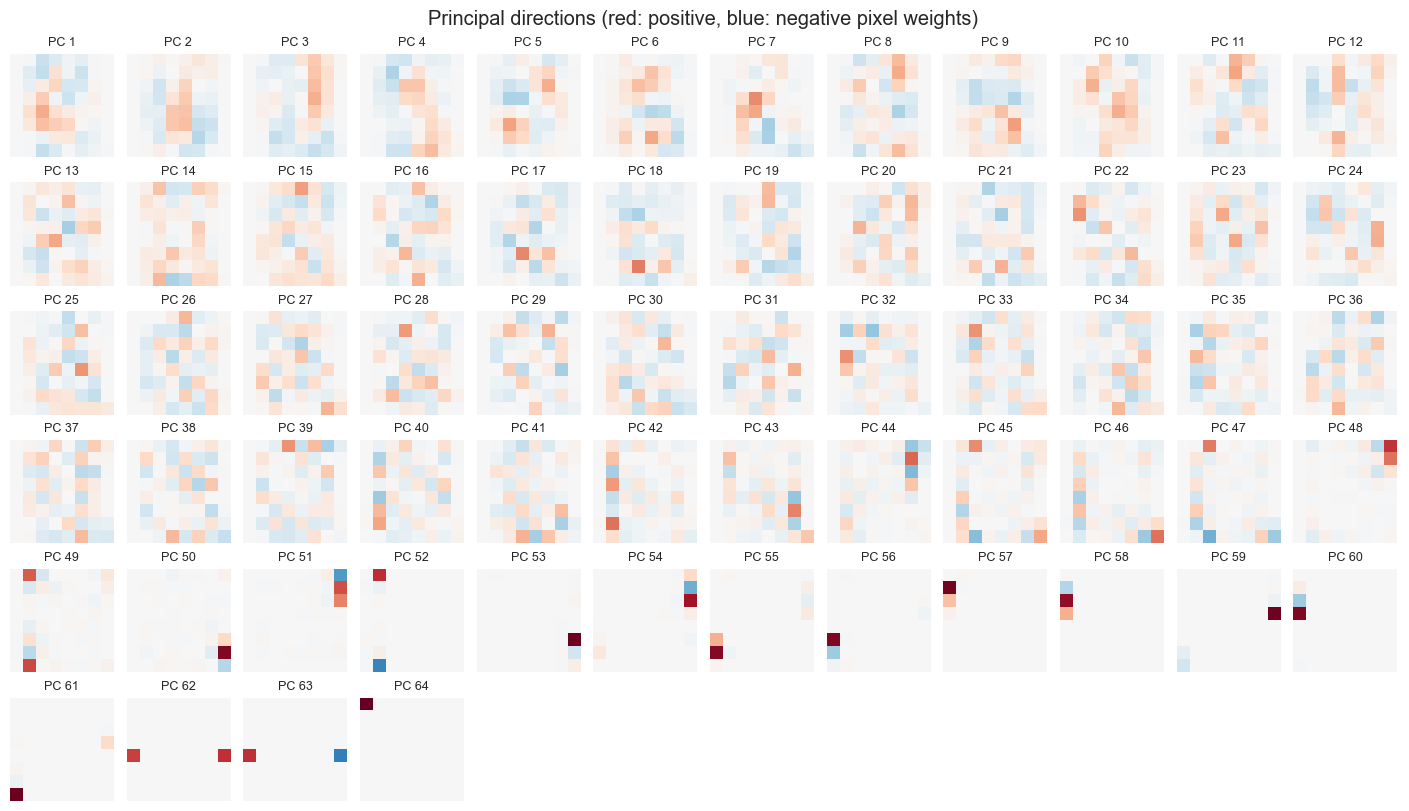

In [20]:
# Display each principal direction as an 8 x 8 image.
pca = pca_full
fig, axes = plt.subplots(6, 12, figsize=(14, 8), constrained_layout=True)
limit = np.abs(pca.components_).max()
for idx, ax in enumerate(axes.flat):
    ax.axis('off')
    if idx < 64:
        ax.imshow(pca.components_[idx].reshape(8, 8), cmap='RdBu_r',
                  vmin=-limit, vmax=limit)
        ax.set_title(f'PC {idx + 1}', fontsize=9)
fig.suptitle('Principal directions (red: positive, blue: negative pixel weights)')
plt.show()

## Question 3.3 What are your observations from the visualized eigen vectors? (5 pts)

### Solution for Question 3.3

The leading eigenvectors show broad, organized patterns of pixel weights, representing changes in stroke positions, orientations, and shapes. Later components explain less variance and tend to show finer or more localized patterns. Each eigenvector is a direction of variation around the mean image, rather than a representative image of a particular digit. Red and blue weights describe pixel intensities that increase and decrease together along that direction; reversing all signs represents the same principal axis.

The explained-variance plot drops rapidly: the first two components retain about 28.51% of the total variance. Keeping 13 components is sufficient for 80%, while 29 are needed for 95%. Thus two components help visualization but discard considerable information. Small-variance components are not necessarily noise; they may contain real details. The final zero-variance directions are not informative patterns, and their displayed basis can be arbitrary.

### Feature reconstruction:

Suppose you only want to preserve $80\%$ variance after applying PCA for the dimension reduction, due to storage issues, etc. 

Clean-data components retained: 13
Variance retained: 80.2896%


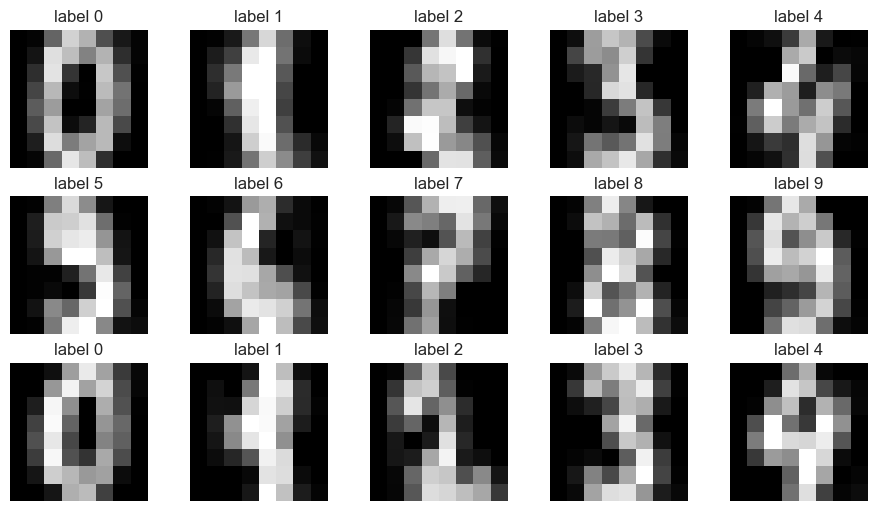

In [21]:
# Fit once, retain at least 80% of the clean-data variance, and reconstruct.
pca_08 = PCA(n_components=0.8, svd_solver='full')
lower_dimension = pca_08.fit_transform(data_digit.data)
reconstructed = pca_08.inverse_transform(lower_dimension)
print(f"Clean-data components retained: {pca_08.n_components_}")
print(f"Variance retained: {pca_08.explained_variance_ratio_.sum():.4%}")
display_digits(reconstructed)

Assume now you are given only a set of perturbed images (with some random noise). As shown below, the figures become much more difficult to recognize.

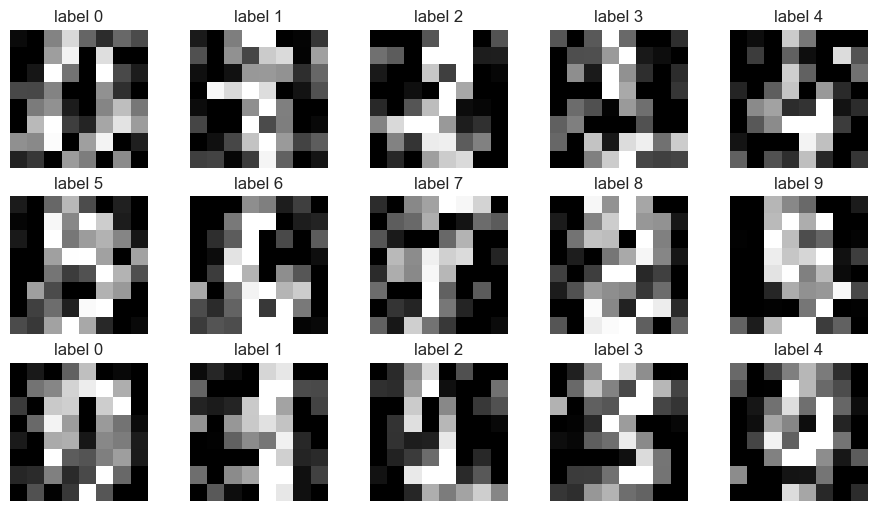

In [22]:
# Independent Gaussian noise with mean zero and standard deviation 5.
rng = np.random.default_rng(0)
noisy_imgs = rng.normal(loc=data_digit.data, scale=5)
display_digits(noisy_imgs)

## Question 3.4 Does PCA mitigate the random noise? (10 pts)

### Your tasks:

- Perform feature reconstruction on <code>noisy\_imgs</code> (preserving $80\%$ variance after applying PCA for the dimension reduction)

- Explain your understandings on why PCA reconstructs cleaner images.

Noisy-data components retained: 40
Variance retained: 80.0368%
Pixel MSE before reconstruction: 25.018192
Pixel MSE after reconstruction:  17.490983


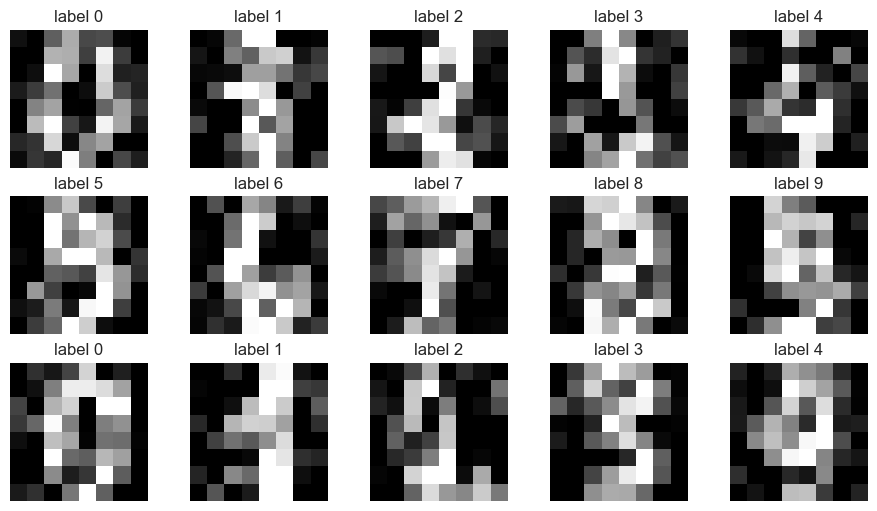

In [23]:
# Question 3.4: learn the PCA subspace from the noisy images themselves.
pca_noise = PCA(n_components=0.8, svd_solver='full')
projected_noise = pca_noise.fit_transform(noisy_imgs)
reconstructed_noise = pca_noise.inverse_transform(projected_noise)
print(f"Noisy-data components retained: {pca_noise.n_components_}")
print(f"Variance retained: {pca_noise.explained_variance_ratio_.sum():.4%}")
# The clean images are used only to assess reconstruction, not to fit PCA.
noisy_mse = metrics.mean_squared_error(data_digit.data, noisy_imgs)
denoised_mse = metrics.mean_squared_error(data_digit.data, reconstructed_noise)
print(f"Pixel MSE before reconstruction: {noisy_mse:.6f}")
print(f"Pixel MSE after reconstruction:  {denoised_mse:.6f}")
display_digits(reconstructed_noise)

### Written answer for Question 3.4

Yes, PCA reduces the average error for this noise realization. Fitting PCA to the noisy images and retaining 80% of their variance selects **40 components out of 64**, retaining 80.04% of the noisy-data variance. The pixel MSE relative to the clean images falls from **25.018192** to **17.490983** (a reduction of 30.09%).

PCA projects each centered noisy image onto the retained principal directions and then maps it back to pixel space. Digit strokes create correlated variation across pixels. Independent, equal-variance Gaussian noise spreads its variance across all directions, so discarding lower-variance directions can remove some noise while preserving much of the shared digit structure. This reduces some speckling, although reconstructed digits still contain noise and may lose fine stroke details.

The 80% threshold refers to the variance of the **noisy** data, which includes noise. Consequently, more components are needed than for clean data, and some noise is retained. PCA does not identify noise directly or guarantee cleaner reconstructions for every image. Here the lower average pixel MSE relative to the original clean images provides quantitative evidence that it helps.

### Resources and assistance acknowledgment

I used ChatGPT/Codex (OpenAI) to draft the mathematical derivations and written explanations, complete the Python code, generate the plots, and execute and check the notebook. The supplied assignment notebook and Advertising.csv are the task and data sources. The scikit-learn [PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) was consulted for PCA parameters and attributes. No external solution sources were used.
